## Importing the dataset

In [ ]:
# !pip install requests

In [ ]:
import requests

try:
  response = requests.get("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt")

  with open("data-input.txt", "a", encoding="utf-8") as file:
    file.writelines(response.text)

except Exception as e:
  print(e)


In [ ]:
!head data-input.txt

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:


### Creating the Vocabulary Space

In [ ]:
with open("/content/data-input.txt","r") as file:
  data = file.read()

## Data Prep Class

In [ ]:
from sklearn.model_selection import train_test_split
import torch
import math

class DataPrep:
    def __init__(self, data):
        self.hash_set = set(data)
        self.hash_set.add("?")  # Unknown character

        self.vocab_list = sorted(self.hash_set)

        self.vocab_size = len(self.vocab_list)
        self.embed_dim = 32
        self.seq_len = 32
        self.batch_size=64

        self.stoi = {
            c: i for i, c in enumerate(self.vocab_list)
        }
        self.itos = {
            i: c for i, c in enumerate(self.vocab_list)
        }

    def encode(self, text):
        return [self.stoi.get(c, self.stoi["?"]) for c in text]

    def decode(self, integers):
        return "".join(self.itos.get(i, "?") for i in integers)

    def split_data(self, data):
        split_idx = int(len(data) * 0.8)

        train_text = data[:split_idx]
        test_text = data[split_idx:]

        return torch.tensor(self.encode(train_text)), torch.tensor(self.encode(test_text))


dataPrep = DataPrep(data)

train, test = dataPrep.split_data(data)

print(f"Length of train: {len(train)} and test: {len(test)}")

Length of train: 892315 and test: 223079


## Model


In [ ]:
import torch
from torch import nn

class cLLM(nn.Module):
  def __init__(self, vocab_size, embed_dim, seq_len):
    super().__init__()
    self.seq_len = seq_len
    self.embedding = nn.Embedding(vocab_size, embed_dim)
    self.pos_embedding = nn.Embedding(seq_len, embed_dim)
    self.linear = nn.Linear(in_features=embed_dim, out_features=vocab_size)
    self.optimizer = torch.optim.SGD(self.parameters(), lr=0.01, momentum=0.9)
    self.criterion = nn.CrossEntropyLoss()
    self.attention = Attention(embed_dim=embed_dim)

    self.pre_attention_norm = nn.LayerNorm(embed_dim)
    self.pre_mlp_norm = nn.LayerNorm(embed_dim)

    self.feedForward = FeedForward(embed_dim)

  def forward(self, batch_input):
    embedded_data = self.embedding(batch_input)
    positions = torch.arange(0,batch_input.shape[1])
    position_data = self.pos_embedding(positions)

    pos_embed_data = embedded_data+position_data

    pre_attention_norm = self.pre_attention_norm(pos_embed_data)

    attention_mat = self.attention(pre_attention_norm)
    resuidal = attention_mat + pos_embed_data

    pre_mlp_norm = self.pre_mlp_norm(resuidal)

    mlp = self.feedForward(pre_mlp_norm)

    residial = mlp+resuidal
    # print(embedded_data.shape) (8,16,16)
    # print(pos_embed_data.shape)
    logits = self.linear(residial)
    return logits

  def validate(self, batch_input, batch_target):
    self.eval()
    with torch.no_grad():
      logits = self(batch_input=batch_input)
      logits = logits.permute(0, 2, 1)

      loss = self.criterion(logits,batch_target.long())

      return loss.item()

  def train_step(self, batch_input, batch_target):
    self.train()
    self.optimizer.zero_grad()


    logits = self(batch_input)

        # CrossEntropyLoss expects [B, V, T] for sequence logits
    logits = logits.permute(0, 2, 1)

    loss = self.criterion(logits,batch_target.long())

    loss.backward()
    self.optimizer.step()

    return loss.item()

  def generate(self, prompt, max_new_tokens, stoi, itos):
    self.eval()

    input_ids = torch.tensor(
        [stoi[c] for c in prompt], dtype=torch.long
    ).unsqueeze(0)

    with torch.no_grad():
      for _ in range(max_new_tokens):
        context = input_ids[:,-self.seq_len:]

        logits = self(context)

        next_char_logits = logits[:,-1,:]

        # top_logits, top_indices = torch.topk(next_char_logits, k=5, dim=-1)
        # top_probs = torch.softmax(next_char_logits, dim=-1).gather(1, top_indices)

        # print("Context:", itos[int(i)] if False else print("Context : ", ''.join(itos[idx] for idx in input_ids[0].tolist())[-30:]))
        # for idx, prob in zip(top_indices[0].tolist(), top_probs[0].tolist()):
        #     print(f"Character: {repr(itos[idx])}, Probability: {prob:.4f}")

        next_char_prob = torch.softmax(next_char_logits, dim=-1)

        next_char_id = torch.multinomial(next_char_prob,1)
        # next_char_id = torch.argmax(next_char_logits,dim=-1, keepdim=True)

        input_ids = torch.cat([input_ids,next_char_id],dim=1)

    generated_id = input_ids[0].tolist()
    return ''.join(itos[idx] for idx in generated_id)



In [ ]:
model = cLLM(dataPrep.vocab_size, dataPrep.embed_dim, dataPrep.seq_len)

In [ ]:
model.embedding

Attention Class

In [ ]:
class Attention(nn.Module):
  def __init__(self, embed_dim):
    super().__init__()
    self.Qw = nn.Linear(embed_dim, embed_dim)
    self.Kw = nn.Linear(embed_dim, embed_dim)
    self.Vw = nn.Linear(embed_dim, embed_dim)
    self.embed_dim = embed_dim

  def forward(self, embedded_data):
    Q = self.Qw(embedded_data)
    K = self.Kw(embedded_data)
    V = self.Vw(embedded_data)

    Kt = torch.transpose(K,-2,-1)
    dot_product = torch.matmul(Q,Kt)
    dot_product = dot_product/math.sqrt(self.embed_dim)

    mask = torch.triu(torch.ones_like(dot_product), diagonal=1).bool()
    dot_product=dot_product.masked_fill(mask, float('-inf'))

    soft_max = nn.functional.softmax(dot_product, dim=-1)
    # print(soft_max[0])
    attention_scores = torch.matmul(soft_max,V)

    return attention_scores


## Feed Forward Class


In [ ]:
class FeedForward(nn.Module):
  def __init__(self, embed_dim):
    super().__init__()
    self.hidden_layer = nn.Linear(embed_dim, 4*embed_dim)
    self.activation_layer = nn.GELU()
    self.output_layer = nn.Linear(4*embed_dim, embed_dim)

    self.feedForward = nn.Sequential(self.hidden_layer, self.activation_layer, self.output_layer)

  def forward(self, residual):
    return self.feedForward(residual)

batch training

In [ ]:
import math

epoch = 20
train_loss_list = []
val_loss_list = []

train_windows = train.unfold(0,dataPrep.seq_len+1,1)
train_inputs = train_windows[:,:-1]
train_targets = train_windows [:,1:]

test_windows = test.unfold(0,dataPrep.seq_len+1,1)
test_inputs = test_windows[:,:-1]
test_targets = test_windows[:,1:]

N_train = len(train_inputs)
N_test = len(test_inputs)

batch_size = dataPrep.batch_size

batches_per_epochT = math.ceil(N_train/batch_size)
batches_per_epochV = math.ceil(N_test/batch_size)


for epoch in range(epoch):
  print(f"---------------------Epoch {epoch}-----------------------------")

  shuffled_train_index = torch.randperm(N_train)
  shuffled_test_index = torch.randperm(N_test)
  train_loss = 0
  val_loss = 0

  print("Prepared the dataset ----- Starting the training loop")

  for start in range(0, N_train, batch_size):
    batch_train_index = shuffled_train_index[start:start+batch_size]

    x = train_inputs[batch_train_index]
    y = train_targets[batch_train_index]

    train_loss+=model.train_step(x,y)

  print(f"Avg Loss = {train_loss/batches_per_epochT:.4f}")
  train_loss_list.append(train_loss/batches_per_epochT)


  for start in range(0, N_test, batch_size):
    batch_test_index = shuffled_test_index[start:start+batch_size]

    x = test_inputs[batch_test_index]
    y = test_targets[batch_test_index]

    val_loss += model.validate(x,y)

  print(f"Avg Val loss = {val_loss/batches_per_epochV:.4f}")
  val_loss_list.append(val_loss/batches_per_epochV)


  print(f"Total Train Loss After {epoch} Epoch : {sum(train_loss_list)/len(train_loss_list)}")
  print(f"Total Val Loss After {epoch} Epoch : {sum(val_loss_list)/len(val_loss_list)}")

  if epoch%5==0:
    prompt = "love"
    stoi = dataPrep.stoi
    itos = dataPrep.itos

    print("Generated Tex : ",model.generate(prompt,100,stoi,itos))

---------------------Epoch 0-----------------------------
Prepared the dataset ----- Starting the training loop
Avg Loss = 2.6052
Avg Val loss = 2.5507
Total Train Loss After 0 Epoch : 2.6051697773940936
Total Val Loss After 0 Epoch : 2.550721113393174
Generated Tex :  love d le chavarer.
Yh'sesene:

I torer t he h ove an, f t ouor mes an utherearshar owet ugr


Ante. rou
---------------------Epoch 1-----------------------------
Prepared the dataset ----- Starting the training loop
Avg Loss = 2.4884
Avg Val loss = 2.5177
Total Train Loss After 1 Epoch : 2.5467725501069376
Total Val Loss After 1 Epoch : 2.534211819909184
---------------------Epoch 2-----------------------------
Prepared the dataset ----- Starting the training loop
Avg Loss = 2.4672
Avg Val loss = 2.5029
Total Train Loss After 2 Epoch : 2.520241503387637
Total Val Loss After 2 Epoch : 2.5237801149758217
---------------------Epoch 3-----------------------------
Prepared the dataset ----- Starting the training loop
Avg Los

single head self attention mechanism

In [ ]:
prompt = "love"
stoi = dataPrep.stoi
itos = dataPrep.itos

print(model.generate(prompt,100,stoi,itos))

lovet, y wethals tarets bernt wit
CEaver thsee haro iuried ad nch fothou show:
A baud I Ins touicth.
Gra


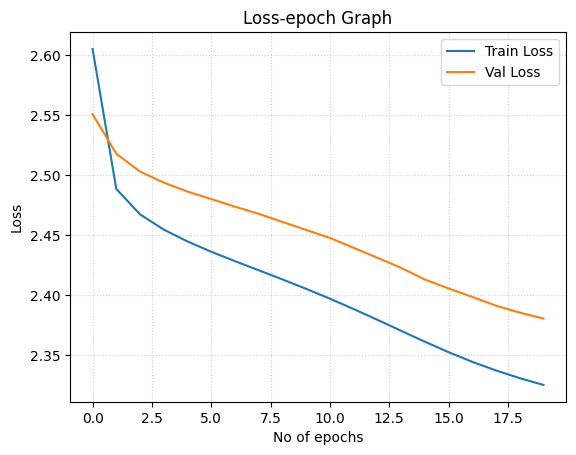

In [ ]:
import matplotlib.pyplot as plt

x = range(epoch+1)

plt.plot(x, train_loss_list, label = "Train Loss")
plt.plot(x, val_loss_list, label = "Val Loss")

plt.xlabel('No of epochs')
plt.ylabel('Loss')
plt.title('Loss-epoch Graph')
plt.legend() # Automatically shows the labels assigned in steps 2 and 3
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()